# Mixed-mode delamination with large-scale fibre bridging at a 45//-45 interface: MMB tests of T700/QY9511

Tests: Y. Gong, L. Zhao, J. Zhang, Y. Wang and N. Hu, *Delamination propagation criterion including the effect of fiber bridging for mixed-mode I/II delamination in CFRP multidirectional laminates*, Compos. Sci. Technol. 2017; 151:302-309, https://doi.org/10.1016/j.compscitech.2017.09.002.

The same test campaign is reported in L. Zhao, Y. Gong, J. Zhang, Y. Chen and B. Fei, *Simulation of delamination growth in multidirectional laminates under mode I and mixed mode I/II loadings using cohesive elements*, Compos. Struct. 2014; 116:509-522, https://doi.org/10.1016/j.compstruct.2014.05.042; Y. Gong, L. Zhao, J. Zhang and N. Hu, *An improved power law criterion for the delamination propagation with the effect of large-scale fiber bridging in composite multidirectional laminates*, Compos. Struct. 2018; 184:961-968, https://doi.org/10.1016/j.compstruct.2017.10.076; and Y. Gong, H. Zhang, L. Jiang, Z. Ding and N. Hu, *Determination of mixed-mode I/II fracture toughness and bridging law of composite laminates*, Theor. Appl. Fract. Mech. 2023; 127:104060, https://doi.org/10.1016/j.tafmec.2023.104060. FE re-analysis: C. Fu and X. Wang, *Simulating delamination in composite laminates involving large scale fiber bridging based on the mixed-mode three-linear cohesive zone model*, Theor. Appl. Fract. Mech. 2022; 117:103164, https://doi.org/10.1016/j.tafmec.2021.103164. Mode I bridging law: Y. Gong, Y. Hou, L. Zhao, W. Li, J. Zhang and N. Hu, *A modified mode I cohesive zone model for the delamination growth in DCB laminates with the effect of fiber bridging*, Int. J. Mech. Sci. 2020; 176:105514, https://doi.org/10.1016/j.ijmecsci.2020.105514.

Carbon/bismaleimide T700/QY9511 specimens, $(+45/-45/0_6)_S//(-45/+45/0_6)_S$, with the delamination at a $45//-45$ interface, tested in the mixed-mode bending (MMB) configuration at $G_{II}/G$ = 25, 40, 50, 60 and 75%, one specimen per ratio. Fibre bridging raises the mode I toughness from 0.100 to 0.890 N/mm over a bridging zone of about 26 mm.

`panels` models the five tests with the coupons of `panels.multidomain.delamination.create_coupon`, two plate arms joined by superposed mixed-mode bilinear cohesive laws (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)): a crack-tip law and a bridging law driven by the opening alone and without shear stiffness, with CLPT and with FSDT arms. The bridging law is **identified from the DCB** of the same laminate, so the MMB analyses are predictions.

The four papers contradict each other in three values; the choices made here are **identifications**, stated in the next section with their basis.

In [1]:
%matplotlib inline
import math
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import law_with_ratio

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case4b_gongzhao')
# comma-separated keys, e.g. MMB50_clpt, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties: $E_{11}$ = 130 GPa, $E_{22} = E_{33}$ = 10.4 GPa, $\nu_{12}$ = 0.3 (Gong et al. 2017, Sec. 3.1, p. 3; Zhao et al. 2014, p. 5), $G_{12} = G_{13}$ = 6.63 GPa (Gong et al. 2018, Sec. 3.1, p. 2; Fu and Wang 2022, p. 5, print 6.36 GPa, a digit swap). **Assumed:** $G_{23}$ = 3.7 GPa $= E_{22}/(2(1+\nu_{23}))$ with $\nu_{23}$ = 0.4 (not published; only the FSDT arms use it).
- Specimen: width 25 mm, thickness $2h$ = 4.16 mm, 180 mm long, Teflon insert 35 mm (Gong et al. 2017, p. 3). The ply thickness, 0.13 mm = 4.16/32, is inferred. Upper arm $(+45/-45/0_6)_S$, lower arm $(-45/+45/0_6)_S$ (Gong et al. 2018, 2023); `create_coupon` takes one stack for both arms, so both arms are $(+45/-45/0_6)_S$ here (with the lower arm mirrored the study found the load within 0.1%).
- MMB: half-span $L$ = 55 mm (Gong et al. 2018, p. 3; Zhao et al. 2014, p. 6), lever lengths $c$ = 89, 57.3, 47, 40.4 and 32.8 mm (Gong et al. 2018, p. 3; Gong et al. 2023, p. 5); crack lengths $a_0$ = 36.48, 35.70, 35.69 and 38.70 mm, measured (Gong et al. 2023, Table 1, p. 6), and 35 mm at 75%, the insert length (not measured for this ratio). The tests were stopped at $a = L - 3h$ = 48.76 mm (Gong et al. 2018, p. 3). The lever weight is not published and not modelled.
- Crack-tip law: $G_{Ic}$ = 0.100 N/mm (DCB initiation, Gong et al. 2017, p. 4), $G_{IIc}$ = 0.7833 N/mm (see below), exponent $\eta$ = 3.75 (Gong et al. 2017, p. 6, fitted with the R-curves; the only published exponent), $\tau_I$ = 50 and $\tau_{II}$ = 90 MPa (Gong et al. 2017, p. 5; numerical choices of the authors), $K_I = 10^5$ N/mm$^3$ (production value of the study; the papers use $10^6$ N/mm$^3$).
- **Bridging law, identified from the DCB:** strength $\sigma_b$ = 2.1 MPa (Gong et al. 2020, Table 1, p. 5, DCB of the same $45//-45$ laminate; also Fu and Wang 2022, Table 2) and toughness $G_{br} = G_{prop} - G_{init}$ = 0.890 - 0.100 = 0.790 N/mm (Gong et al. 2017, p. 4); linear softening that starts where the crack-tip law fails, $\delta_b = 2G_{Ic}/\tau_I$ = 0.004 mm (Gong et al. 2020, Sec. 2.2), so its stiffness is $\sigma_b/\delta_b$ = 525 N/mm$^3$, and ends at $2G_{br}/\sigma_b$ = 0.752 mm. The bridging length of 26 mm is not an input but an outcome of the model. No MMB result was used, so the MMB analyses are predictions.
- Laws in `panels`: the bridging law is driven by the opening alone and has no shear stiffness or toughness (`opening_driven=True`, `shear_free=True`, `GIIc=0`, the options of `law_with_ratio` and `BilinearLaw`). The crack-tip law is entered as two identical halves (half the toughnesses, strengths and stiffness each, $\tau_{II}$ = 45 MPa each), as in the study, whose driver treats the first two laws as crack-tip laws; superposed identical laws are the same law. Both halves define the crack tip (`tip_laws=[0, 1]`).

### Conflicting published data: identifications

- **Peak load at 50%: 198.2 N** (Gong et al. 2017, Table 1, p. 7, and Gong et al. 2018) is taken as the test value, and 159.9 N (Gong et al. 2023, Table 3, p. 9) as a misprint: every plotted record of this test peaks at 195-198 N, including Fig. 12 of Gong et al. (2023) itself (195.1 N), Gong et al. (2017), Figs. 5(d) and 8(b), Fu and Wang (2022), Fig. 11, and Zhao et al. (2014), Fig. 11(b) and Table 6 (196.26 N); with the compliance of the model, 159.9 N would give a toughness of 0.57-0.59 N/mm against 0.78-0.91 N/mm at every other ratio.
- **Mode II toughness: 0.7833 N/mm.** 0.97757 N/mm (Gong et al. 2017, p. 6) quotes 0.99757 N/mm of Zhao et al. (2014), p. 7, with a transcription error; 0.7833 N/mm is the intercept of the R-curve fit of the four-point ENF test (Gong et al. 2017, Fig. 5(b); Gong et al. 2018, Table 1 at $G_{II}/G$ = 1), a different test. The MMB data cannot decide between them: the study found the load at 75% 1% below the test with 0.7833 and 10% above it with 0.99757 N/mm. 0.7833 N/mm is used, with the exponent 3.75 fitted together with it.
- **Mode I initiation toughness: 0.100 N/mm is used.** It is the value at zero growth of a quadratic fit of the DCB R-curve, below the first measured point (Zhao et al. 2014, p. 7; Gong et al. 2017, Fig. 5(a)); 0.1938 N/mm (Gong et al. 2018, Table 1) is the intercept of a linear fit of the same data. The loads at the onset of damage of Gong et al. (2017), Table 1, favour 0.19 N/mm; in the study, the crack-tip law with 0.1938 N/mm (and $G_{br}$ = 0.696 N/mm, the same propagation toughness) changed the loads at the end of the tests by 0 to -3%.

In [2]:
laminaprop = (130000., 10400., 0.3, 6630., 6630., 3700.)   # E11, E22, nu12, G12, G13, G23
E11, E22, _, _, G13, _ = laminaprop
plyt, stack = 0.13, [45, -45] + [0]*12 + [-45, 45]        # arm (+45/-45/0_6)S, h = 2.08 mm
h = plyt*len(stack)
b, L = 25., 55.
GIc, GIIc, eta, tauI, tauII, KI = 0.100, 0.7833, 3.75, 50., 90., 1e5     # crack-tip law
sigma_b, G_br = 2.1, 0.890 - 0.100                                          # bridging law (DCB)
delta_b = 2*GIc/tauI
K_b = sigma_b/delta_b
# crack-tip law as two identical halves, each with tau_II/2; one ratio kappa for all the laws
half = dict(GIc=GIc/2, GIIc=GIIc*(GIc/2)/GIc, tauI=tauI/2, KI=KI/2)
kappa = (tauII/2/half['tauI'])**2*half['GIc']/half['GIIc']
laws = [law_with_ratio(half['GIc'], half['GIIc'], half['tauI'], half['KI'], eta, kappa, name='tip_a'),
        law_with_ratio(half['GIc'], half['GIIc'], half['tauI'], half['KI'], eta, kappa, name='tip_b'),
        law_with_ratio(G_br, 0., sigma_b, K_b, eta, kappa, name='bridging',
                       opening_driven=True, shear_free=True)]
for l in laws:
    print(l)
print('delta_b = {0:.4f} mm, K_b = {1:.1f} N/mm^3, end of the bridging law {2:.3f} mm'.format(
      delta_b, K_b, 2*G_br/sigma_b))

a_stop = L - 3*h          # crack length at which the tests were stopped
# B = G_II/G (nominal); delta_max: last load-point displacement of the runs
tests = {
    'MMB25': dict(B=0.25, a0=36.48, c=89., delta_max=10.),
    'MMB40': dict(B=0.40, a0=35.70, c=57.3, delta_max=8.),
    'MMB50': dict(B=0.50, a0=35.69, c=47., delta_max=6.),
    'MMB60': dict(B=0.60, a0=38.70, c=40.4, delta_max=5.7),
    'MMB75': dict(B=0.75, a0=35., c=32.8, delta_max=5.),
}

BilinearLaw(GIc=0.05, GIIc=0.39165000000000005, tauI=25.0, tauII=45.00000000000001, KI=50000.0, eta=3.75, KII=20681.73113749521)
BilinearLaw(GIc=0.05, GIIc=0.39165000000000005, tauI=25.0, tauII=45.00000000000001, KI=50000.0, eta=3.75, KII=20681.73113749521)
BilinearLaw(GIc=0.79, GIIc=0.0, tauI=2.1, tauII=0.0, KI=525.0, eta=3.75, KII=0.0, opening_driven=True)
delta_b = 0.0040 mm, K_b = 525.0 N/mm^3, end of the bridging law 0.752 mm


## Reference data

**Peak loads of the tests**, Gong et al. (2017), Table 1, p. 7; Gong et al. (2023), Table 3, p. 9, gives slightly different values (95.4, 158.2, 159.9 and 229.3 N at 25-60%), and Zhao et al. (2014), Table 6, 196.26 N at 50%.

**Load-displacement curves**, digitised from the figures: the test record of each ratio, Gong et al. (2017), Fig. 8(b) (25, 40, 50 and 75%) and Fig. 8(c) (60%), the same record that the other papers plot; the FE analyses of Gong et al. (2017), Fig. 8(b, c) ("improved B-K" criterion with the R-curves), of Gong et al. (2023), Fig. 12 (cohesive law with the bridging law of each ratio), and of Fu and Wang (2022), Fig. 11 (trilinear cohesive law). The FE peaks are the maxima of the digitised curves.

**LEFM** (ASTM D6671) is not computed for this case: its beam formulas assume unidirectional arms, and with large-scale bridging the toughness is not a constant; the study's bilinear laws at the initiation and at the propagation toughness give loads 30-55% below and 21-30% above the tests.

In [3]:
ref_peaks = {'MMB25': 96.9, 'MMB40': 160.5, 'MMB50': 198.2, 'MMB60': 232.3, 'MMB75': 311.9}
fig_test = {'MMB25': 'Gong2017_Fig8b_MMB25', 'MMB40': 'Gong2017_Fig8b_MMB40', 'MMB50': 'Gong2017_Fig8b_MMB50',
            'MMB60': 'Gong2017_Fig8c_MMB60', 'MMB75': 'Gong2017_Fig8b_MMB75'}
fe_files = {'FE, Gong 2017': lambda k: fig_test[k] + '_FE',
            'FE, Gong 2023': lambda k: 'Gong2023_Fig12_{0}_FE'.format(k),
            'FE, Fu 2022': lambda k: 'Fu2022_Fig11_{0}_FE'.format(k)}
curves, fe_curves = {}, {}
for key in tests:
    curves[key] = mu.read_curve(os.path.join(REFERENCE, fig_test[key] + '_exp.csv'))
    fe_curves[key] = {}
    for lab, f in fe_files.items():
        path = os.path.join(REFERENCE, f(key) + '.csv')
        if os.path.exists(path):
            fe_curves[key][lab] = mu.read_curve(path)

## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load): each arm is a cracked domain, seven cohesive domains over 30 mm from the crack tip and a far domain with the same laws; contact over the pre-crack; domains joined with the null-space method. The lever constraint acts on the mean deflections across the width. `panels` computes the full $ABD$ matrices of the arms, with their bending-twisting coupling.

Discretisation, as in the study of the mixed-mode model (rules in `mmb_utils.discretisation`): $m = \min(25, \lceil 1.25\,r L_{dom}\rceil)$ terms along $x$ in each cohesive domain of 4.29 mm, with $r$ the largest decay rate of the opening and the sliding of the arms (for FSDT arms also the fast decay of Timoshenko arms): 6 for CLPT, 23 for FSDT; 25 Gauss points per mm along $x$ (108 per domain), about 18 per cohesive zone length $l_{cz} = 0.88 E_{22} G_{Ic}/\tau_I^2$ = 0.73 mm of the crack-tip law halves; 6 across the width; $n = 4$ terms across the width; 10 terms along $x$ in the cracked and far domains. In the study, 12 and 20 terms in the CLPT cohesive domains changed the curve by 0.1 N, and $n$ = 8 the load by -0.4%.

Solver (`solve_coupon`): Newton-Raphson, displacement increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$, control of the load-point displacement. The compared load is the largest load before the crack reaches $a = L - 3h$, where the tests were stopped.

**Stored results.** The runs were made with this notebook (`MMB_RERUN=1`) on a node of a computing cluster, eight at a time with one thread each; the table at the end gives their run times and the computer.

In [4]:
nd, L_coh, gauss_per_mm = 7, 30., 25.


def inputs_of(key, model):
    t = tests[key]
    disc = mu.discretisation(laminaprop, h, laws, L_coh, nd, model=model)
    return dict(kind='MMB', laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
                laws=[mu.law_dict(l) for l in laws], L=L, c=t['c'], model=model, nd=nd, L_coh=L_coh,
                m_crack=10, m_coh=disc['m_coh'], m_far=10, n=4,
                nr_x_gauss=int(math.ceil(gauss_per_mm*disc['L_dom'])), nr_y_gauss=6, tip_laws=[0, 1])


def solver_of(key):
    return dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)


runs = {}
for key in tests:
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if ONLY is not None and name not in ONLY:
            continue
        path = os.path.join(RESULTS, '{0}_{1}.npz'.format('mmb_gong2017_t700qy9511', name))
        runs[name] = mu.run_or_load(inputs_of(key, model), solver_of(key), path, rerun=RERUN)

## Results

Load of `panels` at the end of the tests (the largest load before $a = L - 3h$; where the crack did not reach it, the largest load of the run), peak loads of the published FE analyses, and the differences to the test peaks of Gong et al. (2017), Table 1.

In [5]:
rows = []
for key, t in tests.items():
    rows.append((key, 'Test, Gong 2017 Table 1', ref_peaks[key]))
    for lab, (d, P) in fe_curves[key].items():
        rows.append((key, lab, float(np.nanmax(P))))
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            reached = res['a'].max() >= a_stop
            rows.append((key, 'panels {0}{1}'.format(model.upper(), '' if reached else ' (a < L - 3h)'),
                         mu.peak_load(res, a_stop)[0]))
display(Markdown(mu.peaks_table(rows, ref='Test, Gong 2017 Table 1')))

| test | source | $P_{max}$ (N) | vs Test, Gong 2017 Table 1 |
|---|---|---|---|
| MMB25 | Test, Gong 2017 Table 1 | 96.9 | - |
| MMB25 | FE, Gong 2017 | 94.6 | -2.4% |
| MMB25 | FE, Gong 2023 | 96.7 | -0.2% |
| MMB25 | FE, Fu 2022 | 100.5 | +3.7% |
| MMB25 | panels FSDT (a < L - 3h) | 111.0 | +14.6% |
| MMB25 | panels CLPT | 111.5 | +15.1% |
| MMB40 | Test, Gong 2017 Table 1 | 160.5 | - |
| MMB40 | FE, Gong 2017 | 157.2 | -2.1% |
| MMB40 | FE, Gong 2023 | 154.8 | -3.5% |
| MMB40 | FE, Fu 2022 | 160.6 | +0.1% |
| MMB40 | panels FSDT | 197.4 | +23.0% |
| MMB40 | panels CLPT | 195.6 | +21.9% |
| MMB50 | Test, Gong 2017 Table 1 | 198.2 | - |
| MMB50 | FE, Gong 2017 | 196.7 | -0.8% |
| MMB50 | FE, Gong 2023 | 196.1 | -1.0% |
| MMB50 | FE, Fu 2022 | 198.4 | +0.1% |
| MMB50 | panels FSDT (a < L - 3h) | 240.8 | +21.5% |
| MMB50 | panels CLPT | 237.9 | +20.0% |
| MMB60 | Test, Gong 2017 Table 1 | 232.3 | - |
| MMB60 | FE, Gong 2017 | 230.6 | -0.7% |
| MMB60 | FE, Gong 2023 | 233.6 | +0.6% |
| MMB60 | panels FSDT | 252.5 | +8.7% |
| MMB60 | panels CLPT | 248.8 | +7.1% |
| MMB75 | Test, Gong 2017 Table 1 | 311.9 | - |
| MMB75 | FE, Gong 2017 | 315.8 | +1.3% |
| MMB75 | FE, Fu 2022 | 309.2 | -0.9% |
| MMB75 | panels FSDT | 313.7 | +0.6% |
| MMB75 | panels CLPT | 309.4 | -0.8% |

Initial stiffness, the slope of the points below 20% of the test peak, N/mm:

In [6]:
def slope_below(d, P, Pcap):
    d, P = np.asarray(d), np.asarray(P)
    m = np.isfinite(d) & np.isfinite(P) & (P <= Pcap)
    m &= np.arange(len(P)) <= np.nanargmax(P)
    return np.polyfit(d[m], P[m], 1)[0]


lines = ['| test | test record | panels FSDT | panels CLPT |', '|---|---|---|---|']
for key in tests:
    k = [slope_below(*curves[key], 0.2*ref_peaks[key])]
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        k.append(np.nan if res is None else slope_below(res['delta'], res['P'], 0.2*ref_peaks[key]))
    lines.append('| {0} | {1:.1f} | '.format(key, k[0]) + ' | '.join(
        '{0:.1f} ({1:+.0f}%)'.format(v, 100*(v/k[0] - 1)) for v in k[1:]) + ' |')
display(Markdown('\n'.join(lines)))

| test | test record | panels FSDT | panels CLPT |
|---|---|---|---|
| MMB25 | 16.8 | 20.7 (+23%) | 22.3 (+33%) |
| MMB40 | 38.9 | 48.2 (+24%) | 51.2 (+32%) |
| MMB50 | 58.9 | 66.7 (+13%) | 70.1 (+19%) |
| MMB60 | 63.4 | 73.6 (+16%) | 76.8 (+21%) |
| MMB75 | 99.3 | 112.0 (+13%) | 115.8 (+17%) |

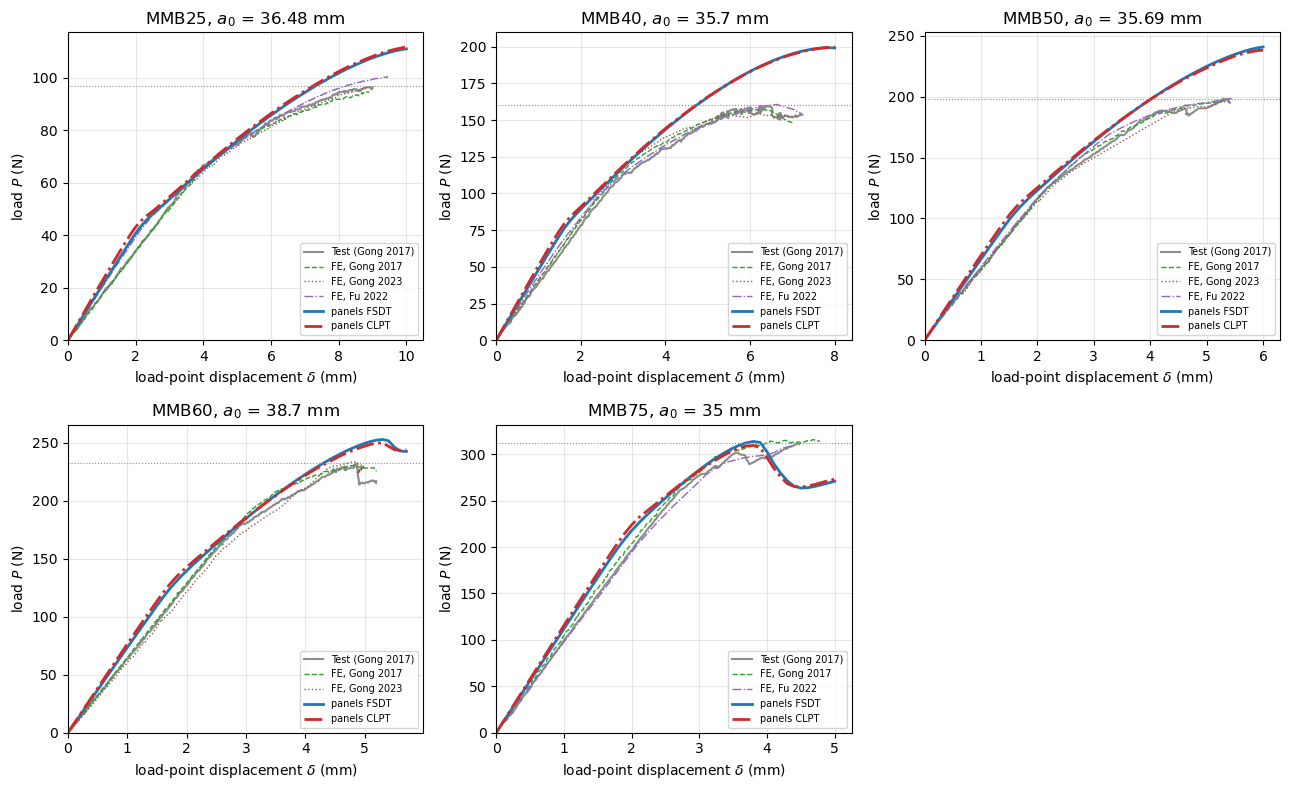

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
fe_style = {'FE, Gong 2017': dict(color='C2', ls='--', lw=1), 'FE, Gong 2023': dict(color='C5', ls=':', lw=1),
            'FE, Fu 2022': dict(color='C4', ls='-.', lw=1)}
for ax, (key, t) in zip(axes.flat, tests.items()):
    cs = {'Test (Gong 2017)': (curves[key][0], curves[key][1], dict(color='0.55', lw=1.5))}
    for lab, (d, P) in fe_curves[key].items():
        cs[lab] = (d, P, fe_style[lab])
    for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            cs['panels ' + model.upper()] = (np.r_[0., res['delta']], np.r_[0., res['P']],
                                             dict(color=col, lw=2, ls='-' if model == 'fsdt' else '-.'))
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1:g} mm'.format(key, t['a0']))
    ax.axhline(ref_peaks[key], color='0.55', lw=0.8, ls=':')
    ax.legend(fontsize=7)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
info = ['| run | status | increments | size | run time (min) | machine |',
        '|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2} | {3} | {4:.1f} | {5} |'.format(
        name, res['status'], len(res['delta']), res['size'], res['time']/60, res['machine']))
display(Markdown('\n'.join(info)))

| run | status | increments | size | run time (min) | machine |
|---|---|---|---|---|---|
| MMB25_fsdt | finished | 100 | 7240 | 29.2 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB25_clpt | finished | 100 | 1488 | 1.3 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB40_fsdt | finished | 80 | 7240 | 27.1 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB40_clpt | finished | 80 | 1488 | 1.4 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_fsdt | finished | 60 | 7240 | 18.9 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB50_clpt | finished | 60 | 1488 | 1.0 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB60_fsdt | finished | 57 | 7240 | 18.8 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB60_clpt | finished | 57 | 1488 | 0.9 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB75_fsdt | finished | 50 | 7240 | 17.5 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |
| MMB75_clpt | finished | 50 | 1488 | 1.0 | Intel(R) Xeon(R) Gold 5218 CPU @ 2.30GHz, 8 logical processors, Linux 3.10.0-1160.119.1.el7.x86_64 |

## Discussion

- **Loads at the end of the tests.** With the bridging law identified from the DCB, the loads at the end of the tests are 15-23% above the tests at 25-50%, 7-9% above at 60% and within 1% at 75%, with CLPT and FSDT arms alike (FSDT within 2% of CLPT). A bilinear law misses the tests by -55 to -30% with the initiation toughness and by +21 to +30% with the propagation toughness (study runs), so the superposition of the crack-tip and bridging laws carries the R-curve. The published FE analyses are within -4 to +4% of the tests, but their laws were calibrated with the MMB tests themselves (bridging law per ratio in Gong et al. 2023, R-curve criteria in Gong et al. 2017).
- **At 75%** the model reaches its largest load at $a \approx$ 43 mm and the crack then grows unstably, while the test load kept rising to the end of the test.
- **Initial stiffness.** `panels` is 13-33% stiffer than the tests. In the study, an independent three-dimensional solid model of the same specimens was within 2.4-2.6% of the FSDT model but still 9-19% stiffer than the tests. The displacements of these tests were measured by the testing machine (Zhao et al. 2014, pp. 5-6), with no reported correction for the compliance of the apparatus; a fibre modulus of 115 GPa instead of 130 GPa would also reproduce the test slopes. The data cannot separate the two. The compliance of the apparatus only shifts $\delta$ and leaves the loads at the end of the tests unchanged; a lower modulus would lower them by about 5% (estimate of the study, not run).
- **Lever weight.** Not published and not modelled. A weight of 0-15 N would lower the loads of the model by 0-15 N (-5 to -15%), and the comparison of the bridging laws depends on it: the model is not adjusted to it.
- **Bridging and the mode ratio.** The bridging law of `panels` keeps the full mode I bridging toughness at every mode ratio. The overprediction at 25-50% is consistent with the bridging fading as the mode II share grows, as in the glass/epoxy tests of Cho et al. (2025) (notebook `mmb_cho2025_glassepoxy`), but here it is entangled with the stiffness gap and the unknown lever weight.
- **Robustness.** All runs reach the last displacement. At 25 and 50% with FSDT arms the crack does not reach $a = L - 3h$ by then (47.95 and 47.85 mm), and the compared load is the largest of the run.